# Amortized methods in geostatistics

**Check list execution**
* data_path
* res_path
* batch_size
* n_epoch

In [12]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

import numpy as np

import random
from tqdm import tqdm
import time
import os
import torchmin
import h5py

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import torch_geometric
from torch_geometric.data import Data
from torch_geometric.nn import global_mean_pool, GCNConv

from torch_geometric.data import Dataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Batch

from torch_geometric.utils import to_scipy_sparse_matrix
from torch_geometric.nn.conv import MessagePassing
from torch_geometric.utils import scatter
from torch_geometric.nn import aggr

In [14]:
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from scipy.optimize import minimize
import scipy.linalg as linalg
from scipy.special import gamma, kv

In [15]:
import gstlearn as gl
import gstlearn.plot as gp
import gstlearn.document as gdoc
gdoc.setNoScroll()

<IPython.core.display.Javascript object>

In [16]:
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

In [17]:
data_path = "data/wallpaper_spatiotemporal_2D_small"
data_name = "samples_square.h5"

os.makedirs(data_path, exist_ok=True)
os.makedirs(data_path+"/samples", exist_ok=True)

In [18]:
# res_path = f"results/{id_path}-{n_train}×{m_train}ntrain-{n_test}×{m_test}ntest" # -{n_points}npoints"
res_path = "results/test_spationtemporal_2D"

os.makedirs(res_path, exist_ok=True)
os.makedirs(res_path+"/loss_evolution", exist_ok=True)
os.makedirs(res_path+"/conclusion_graphs", exist_ok=True)
os.makedirs(res_path+"/models", exist_ok=True)

## Simulation

In [19]:
n_all = 1
sample_size = [30, 30] # [2560,2560]

In [20]:
def simulation_matern(path, n, sizes=[1200,1200], ranges=[1e-2,1e-2]):

    model = gl.Model.createFromParam(gl.ECov.MATERN, ranges = ranges, param = 1, sill = 1**2, flagRange=False)
    
    grid = gl.DbGrid.create(nx = sizes, dx = [1./sizes[0],1./sizes[1]])
    mesh = gl.MeshETurbo(grid)

    pop = gl.PrecisionOp(mesh, model.getCovAniso(0))

    t = tqdm(range(0, n),total=n)

    with h5py.File(path, 'w') as hdf:
        dset = hdf.create_dataset(
            'samples',
            shape=(n, sizes[0], sizes[1]),
            dtype='float64',
            compression='gzip',          
            chunks=(1, sizes[0], sizes[1])
        )
    
        for i in t:
            res = pop.simulateOne()
            dset[i] = res.reshape((sizes[0], sizes[1]))
        


In [21]:
simulation_matern(data_path + '/' + data_name, n=n_all, sizes=sample_size, ranges=[1e-1,1e-1])

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  3.04it/s]


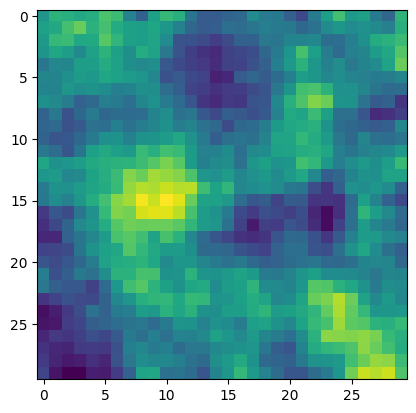

In [22]:
with h5py.File(data_path + '/' + data_name, 'r') as hdf:
    batch = hdf['samples'][0]
plt.imshow(batch)

# width_px = 2560
# height_px = 1440
# dpi = 100

# fig = plt.figure(figsize=(width_px/dpi, height_px/dpi), dpi=dpi)
# ax = plt.Axes(fig, [0., 0., 1., 1.]) 
# fig.add_axes(ax)

# ax.imshow(batch[:1440, :2560], cmap='bone') #cividis # YlGn # Pastel1 # bone # copper
# ax.axis('off')

# plt.savefig(
#     'wallpaper3.png',
#     dpi=dpi,
#     pad_inches=0
# )

# plt.close()

## Load

In [413]:
batch_size = 5
n_epochs = 50
n_epochs_test = 10

In [414]:
space_size = 40
time_size = 40
deepset_size = 4

In [516]:
class GridDataset(Dataset):
    def __init__(self, path, all_idx, deepset_size, time_size = 20, space_size = 20, data_shape=[1200,1200]):
        
        self.path = path
        self.hdf = None
        
        self.all_idx = all_idx
        self.space_size = space_size
        self.time_size = time_size
        self.data_shape = data_shape
        self.deepset_size = deepset_size

        adv = torch.randint(-3,4,(len(all_idx),)) 
        range_space = torch.randint(2,10,(len(all_idx),)) # torch.ones((batch_size,), dtype=int)*1
        range_time = torch.randint(2,10,(len(all_idx),))
        
        self.theta = torch.stack([adv,range_time, range_space]).T

    def __len__(self):
        return len(self.all_idx)


    def _init_hdf(self):
        if self.hdf is None:
            self.hdf = h5py.File(self.path, 'r')

    def __getitem__(self, idx):

        self._init_hdf()

        time_0 = time.time()

        adv = self.theta[idx,0].tile(self.deepset_size)
        range_space = self.theta[idx,1].tile(self.deepset_size)
        range_time = self.theta[idx,2].tile(self.deepset_size)
        

        space_min = torch.maximum(- adv * self.time_size, torch.zeros_like(adv))
        space_max = self.data_shape[1] - torch.maximum(adv * self.time_size, torch.zeros_like(adv)) - self.space_size * range_space
        
        init_space = torch.randint(2**32 - 1, size=(self.deepset_size,)) % (space_max - space_min) + space_min
        init_space = init_space.tile((self.space_size, 1)).T
        init_space += torch.arange(self.space_size).tile((self.deepset_size, 1)) * range_space.unsqueeze(1)
        

        time_max = self.data_shape[0] - range_time * self.time_size
        
        init_time = torch.randint(2**32 - 1, size=(self.deepset_size,)) % time_max
        init_time = init_time.tile((self.time_size, 1)).T
        init_time += torch.arange(self.time_size).tile((self.deepset_size, 1)) * range_time.unsqueeze(1)
        

        space2 = init_space.unsqueeze(1).tile(1,self.time_size, 1)   
        time2  = init_time.unsqueeze(2).tile(1,self.space_size) 

        offset = torch.arange(self.time_size).tile(self.deepset_size,self.space_size,1).transpose(1,2) * adv.unsqueeze(1).unsqueeze(2)
        space2 = space2 + offset
        
        # time_1 = time.time()
        # print("space2 and time2 :",time_1 - time_0)

        theta = torch.stack([adv,range_time, range_space]).T

        deepset = torch.arange(self.deepset_size) # torch.tensor([i for i in range(self.deepset_size) if not(theta[i] in theta[:i])])

        # time_2 = time.time()
        # print("theta and deepset :", time_2 - time_1)

        # idx_rand, _ = torch.sort(torch.randperm(self.all_idx[-1] - self.all_idx[0])[:self.deepset_size])
        start = torch.randint(self.all_idx[0], self.all_idx[-1] - self.deepset_size, (1,)).item()
        idx_rand = torch.arange(start, start + self.deepset_size)
        
        samples = self.hdf['samples']
        batch = samples[idx_rand]
        

        plt.imshow(batch[0].T, origin='lower')
        plt.scatter(space2[0].flatten(), time2[0].flatten(), c='red',s=.1)
        plt.title(theta[0])
        plt.show()
        

        # with h5py.File(self.path, 'r') as hdf:
        #     batch = hdf['samples'][idx_rand] 

        # time_3 = time.time()
        # print("load : ",time_3 - time_2)

        batch = batch[torch.arange(self.deepset_size).unsqueeze(1).unsqueeze(2), time2, space2]

        # time_4 = time.time()
        # print("extract : ",time_4 - time_3)
        
        return (torch.from_numpy(batch), theta, deepset)           

In [517]:
dataset_grid = GridDataset(data_path + '/' + data_name, torch.arange(180), deepset_size, time_size = 40, space_size = 20)
dataset_grid_test = GridDataset(data_path + '/' + data_name, torch.arange(180, 200), deepset_size)

loader_grid = DataLoader(
    dataset_grid,
    batch_size=batch_size,
    shuffle=True,
    # num_workers=4,        
    # persistent_workers=True,
    # collate_fn=collate_fn
)
loader_grid_test = DataLoader(dataset_grid_test, 20, shuffle=False)

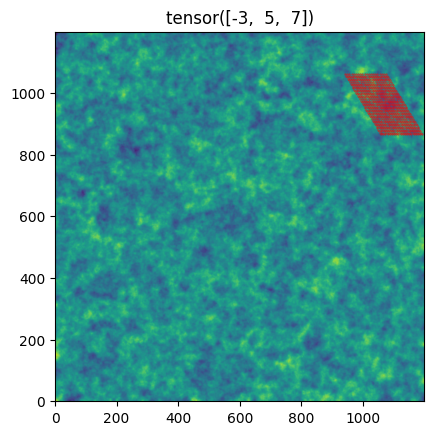

In [518]:
# batch_test = dataset_grid[1]
# plt.imshow(batch_test[0][0])
# print(batch_test[1])
batch_test = dataset_grid[9]

In [515]:
fig, ax = plt.subplots(figsize=(5,5))

def update(i):
    ax.cla()
    ax.imshow(batch_test[0][i])
    # ax.set_xlim(0,1)
    # ax.set_ylim(0,1)
    ax.set_title(f"Theta {batch_test[1][i]}")

ani = FuncAnimation(fig, update, frames=len(batch_test[0]), interval=300)

plt.close()

HTML(ani.to_jshtml())

## Simulation and Load 2

In [23]:
batch_size = 10
n_epochs = 100
n_epochs_test = 10

In [24]:
space_size = 30
time_size = 30
deepset_size = 5

train_size = 200 # 1000
test_size = 20 # 100

In [25]:
def simulate_matern_grid(time_size, space_size, adv, range_time, range_space, std, deepset_size=5):
    model = gl.Model.createFromParam(gl.ECov.MATERN, ranges = [range_time,range_space], param = 1, sill = std**2, flagRange=False)

    shape_adv = abs(adv)+1

    grid = gl.DbGrid.create(
        nx = [time_size,space_size  + time_size*shape_adv],    
        dx = [1./time_size,1./space_size]
    )

    mesh = gl.MeshETurbo(grid)

    pop = gl.PrecisionOpMatrix(mesh, model.getCovAniso(0))

    batch = []
        
    for i in range(deepset_size):
            
        res = pop.simulateOne()
        res = res.reshape((time_size,space_size + time_size*shape_adv), order='F')

        t, s = np.meshgrid(np.arange(time_size), np.arange(space_size), indexing='ij')
        offset = t.copy() * abs(adv)
        s = s + offset


        if adv >= 0 :
            res = res[t,s]
        else :
            res = np.fliplr(res)
            res = res[t,s]
            res = np.fliplr(res)
            
        batch.append(res)

    return np.stack(batch)

In [26]:
class GridDataset(Dataset):
    def __init__(self, theta_size=200, time_size=40, space_size=40, deepset_size=5):

        self.time_size = time_size
        self.space_size = space_size
        
        self.theta_size = theta_size
        self.deepset_size = deepset_size

        self.adv = np.random.randint(-3,4,(theta_size,)) # np.ones((theta_size,), dtype=int)*-1
        self.range_time = np.random.uniform(0.05,0.25,(theta_size,)) 
        self.range_space = np.random.uniform(0.05,0.25,(theta_size,))
        self.std = np.random.uniform(0.05,0.25,(theta_size,))
        
        # self.theta = np.stack([adv,range_time, range_space]).T
        # print(self.theta)

    def __len__(self):
        return self.theta_size

    def get_theta(self):
        return torch.from_numpy(np.stack([self.adv,self.range_time, self.range_space, self.std]).T)

    def save(self, path):
        param = {
            "time_size" : self.time_size,
            "space_size" : self.space_size,
            "theta_size" : self.theta_size,
            "deepset_size" : self.deepset_size,
            "adv" : self.adv,
            "range_time" : self.range_time,
            "range_space" : self.range_space,
        }
        torch.save(param, path)

    def __getitem__(self, idx):

        batch = simulate_matern_grid(
            self.time_size, self.space_size, 
            self.adv[idx], self.range_time[idx], self.range_space[idx],
            self.std[idx],
            self.deepset_size
        )

        theta = self.get_theta()[idx].tile(self.deepset_size,1)

        deepset = torch.ones(self.deepset_size, dtype=int) * idx # torch.tensor([i for i in range(self.deepset_size) if not(theta[i] in theta[:i])])

        return (torch.from_numpy(batch), theta, deepset)           

In [44]:
dataset_grid = GridDataset(theta_size=train_size, time_size=time_size, space_size=space_size, deepset_size=deepset_size)
dataset_grid_test = GridDataset(theta_size=test_size, time_size=time_size, space_size=space_size, deepset_size=1)

loader_grid = DataLoader(dataset_grid, batch_size, shuffle=True)
loader_grid_test = DataLoader(dataset_grid_test, test_size, shuffle=False)

In [45]:
dataset_grid.save(data_path + '/' + data_name)
dataset_grid_test.save(data_path + '/' + data_name)

Text(0.5, 1.0, '[3.         0.10491159 0.10840209]')

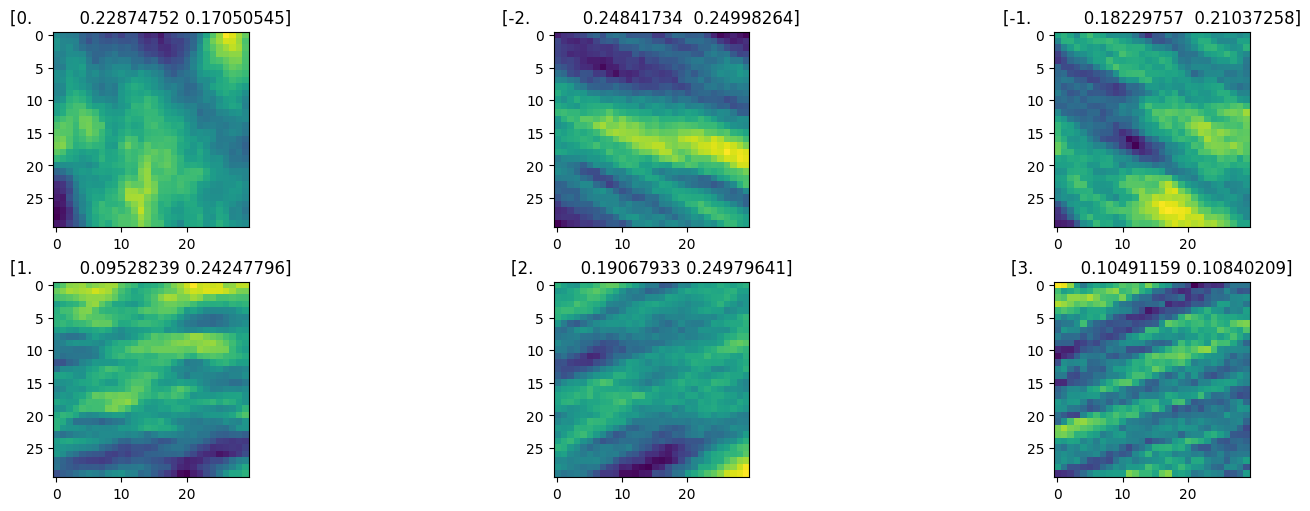

In [46]:
fig, ax = plt.subplots(2, 3, figsize=(15, 5), constrained_layout=True)
ax[0,0].imshow(dataset_grid[0][0][m], aspect='equal')
ax[0,0].set_title(dataset_grid[0][1][m].detach().numpy())
ax[0,1].imshow(dataset_grid[1][0][m], aspect='equal')
ax[0,1].set_title(dataset_grid[1][1][m].detach().numpy())
ax[0,2].imshow(dataset_grid[2][0][m], aspect='equal')
ax[0,2].set_title(dataset_grid[2][1][m].detach().numpy())
ax[1,0].imshow(dataset_grid[3][0][m], aspect='equal')
ax[1,0].set_title(dataset_grid[3][1][m].detach().numpy())
ax[1,1].imshow(dataset_grid[4][0][m], aspect='equal')
ax[1,1].set_title(dataset_grid[4][1][m].detach().numpy())
ax[1,2].imshow(dataset_grid[5][0][m], aspect='equal')
ax[1,2].set_title(dataset_grid[5][1][m].detach().numpy())

## Simulation and Load 3

## Utils

In [16]:
def unique_preserve_order(x):
    seen = []
    out = []
    for v in x.tolist():
        if v not in seen:
            seen.append(v)
            out.append(v)
    return torch.tensor(out, device=x.device)


def map_deepset(deepset, theta):
    unique_ds = unique_preserve_order(deepset)

    deepset_mapped = torch.tensor(
        [unique_ds.tolist().index(int(ds)) for ds in deepset],
        device=device
    )

    theta = torch.stack([theta[deepset == v][0] for v in unique_ds])

    return deepset_mapped, theta

In [17]:
def baseline_mae(dataset):
    all_thetas = dataset.get_theta()
    
    theta_mean = all_thetas.mean(dim=0) 
    
    preds = theta_mean.unsqueeze(0).repeat(len(dataset), 1)
    
    mae = torch.mean(torch.abs(preds - all_thetas),dim=0)

    return mae, theta_mean

## General functions

In [63]:
class CNN_network(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=3, option="2D-CNN", nls=False):
        super().__init__()

        self.option_type = option
        self.nls = nls

        if option == "2D-CNN" : 
        
            self.conv2d = nn.Sequential(
                nn.Conv2d(in_channels=in_channels, out_channels=hidden, kernel_size=5, stride=1, padding=1),
                nn.ReLU(),
                nn.Conv2d(in_channels=hidden, out_channels=hidden, kernel_size=3, stride=1, padding=1),
                nn.ReLU(),
            )
            
            self.pool2d = nn.AdaptiveAvgPool2d(1) 

        else : 

            self.conv1d = nn.Sequential(
                nn.Conv1d(in_channels=in_channels, out_channels=hidden, kernel_size=5, stride=1, padding=1),
                nn.ReLU(),
                nn.Conv1d(in_channels=hidden, out_channels=hidden, kernel_size=3, stride=1, padding=1),
                nn.ReLU(),
            )
            
            self.pool1d = nn.AdaptiveAvgPool1d(1) 
    
            if option == "CNN" :
            
                self.conv1d_T = nn.Sequential(
                    nn.Conv1d(in_channels=hidden, out_channels=hidden, kernel_size=5, stride=1, padding=1),
                    nn.ReLU(),
                    nn.Conv1d(in_channels=hidden, out_channels=hidden, kernel_size=3, stride=1, padding=1),
                    nn.ReLU(),
                )
    
            elif option == "LSTM" :
    
                self.lstm = nn.LSTM(input_size=hidden, hidden_size=hidden, num_layers=2, batch_first=True, bidirectional=False)  

        
        self.dense = nn.Sequential(
            nn.Linear(hidden+3*nls, hidden),
            nn.ReLU(),
            nn.Linear(hidden, out_dim)  
        )

    def forward(self, x, deepset=None, theta=None):
        
        B,C,T,S = x.shape

        # print(x.shape)

        if self.option_type == "2D-CNN" :

            summary = self.conv2d(x)

            summary = self.pool2d(summary).view(B, -1)

        else : 

            x = x.permute(0,3,1,2).reshape(B*T, C, S)  
    
            # print(x.shape)
    
            time_summary = self.conv1d(x)                               # (B*T,hidden_dim,S)
            time_summary = self.pool1d(time_summary).view(B*T,-1)       # (B*T,hidden_dim)
    
            # print(time_summary.shape)
    
            time_summary = time_summary.view(B, T, -1).permute(0, 2, 1)                        # (B, hidden_dim, T)
    
            # print(time_summary.shape)
    
            if self.option_type == "CNN":
                summary = self.conv1d_T(time_summary)            # (B,hidden+1,T)
                summary = summary.mean(dim=2)                    # (B,hidden+1)
                
            elif self.option_type == "LSTM":    
                time_summary = time_summary.permute(0,2,1)       # (B,T,hidden+1)
                summary,_ = self.lstm(time_summary)              # (B,T,hidden+1)
                summary = summary.mean(dim=1)                    # (B,hidden+1)
    
        # print(summary.shape)
    
        if not self.nls :
            summary = global_mean_pool(summary, deepset)   # [nb_deepset, hidden_dim]
        else :
            summary = torch.cat((summary, theta.float()),dim=1)

        # print(summary.shape)
        
        out = self.dense(summary)
        return out

In [178]:
class CNN_network_test(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=3, nls=False):
        super().__init__()

        self.nls = nls

        # self.conv2d = nn.Sequential(
        #     nn.Conv2d(in_channels, hidden, (3,7), padding=(1,3)),
        #     nn.ReLU(),
        #     nn.Conv2d(hidden, hidden, 3, padding=(1,2), dilation=(1,2)),
        #     nn.ReLU(),
        # )
        self.conv2d = nn.Sequential(
            nn.Conv2d(in_channels=in_channels, out_channels=hidden, kernel_size=5, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden, out_channels=hidden, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
        )
            
        self.pool2d = nn.AdaptiveAvgPool2d(1) 

        # self.resblock = nn.Conv2d(in_channels, hidden, kernel_size=1)
        
        self.dense = nn.Sequential(
            nn.Linear(hidden+3*nls, hidden),
            nn.ReLU(),
            nn.Linear(hidden, out_dim)  
        )

    def forward(self, x, deepset=None, theta=None):

        B,C,T,S = x.shape

        # print(x.shape)

        summary = self.conv2d(x)

        # print(summary.shape)

        # summary = summary + self.resblock(x)

        summary = self.pool2d(summary).view(B, -1)
    
        # print(summary.shape)
    
        if not self.nls :
            summary = global_mean_pool(summary, deepset)   # [nb_deepset, hidden_dim]
        else :
            summary = torch.cat((summary, theta.float()),dim=1)

        # print(summary.shape)
        
        out = self.dense(summary)
        return out

In [19]:
def train_test(model, optimizer, loader, epoch_loss):
    all_loss_train_grid = [] 
    all_loss_test_grid = []

    loss_final_train_grid = None
    theta_final_test_grid = None
    
    t = tqdm(range(0, n_epochs),total=n_epochs)
    
    time_train_grid = time.time()
    
    for epoch in t:
        
        losses = epoch_loss(model, optimizer, loader, save_full=(epoch == n_epochs-1))
    
        t.set_description(f"Epoch {epoch+1}/{n_epochs}")
        t.set_postfix(loss=f"{losses["mean"][0]:.4f}, {losses["mean"][1]:.4f} and {losses["mean"][2]:.4f}")

        all_loss_train_grid.append(losses["mean"])   

        if "full" in losses:                          
            loss_final_train_grid = losses["full"] 
            
        if (epoch+1)%n_epochs_test == 0 :
                
            time_test_grid = time.time()
                
            for data_test, theta_test, deepset_test in loader_grid_test :

                data_test = data_test.reshape(-1, 1, data_test.shape[2], data_test.shape[3])   
                theta_test = theta_test.reshape(-1, theta_test.shape[2])   
                deepset_test = deepset_test.reshape(-1)    
                    
                output = model(data_test.float(), torch.arange(len(theta_test)))
                loss_vec = torch.abs(output - theta_test)

                all_loss_test_grid.append(loss_vec.mean(dim=0).detach().cpu())

                theta_final_test_grid = output.detach().cpu()
                    
            time_test_grid = time.time() - time_test_grid
            time_train_grid -= time_test_grid
    
    time_train_grid = time.time() - time_train_grid
    
    print(f"Time to train : {time_train_grid:.2f}s")
    
    print(f"Train loss : adv {all_loss_train_grid[-1][0].tolist()} | range time {all_loss_train_grid[-1][1].tolist()} | range space {all_loss_train_grid[-1][2].tolist()}")

    print(f"Test loss : adv {all_loss_test_grid[-1][0].tolist()} | range time {all_loss_test_grid[-1][1].tolist()} | range space {all_loss_test_grid[-1][2].tolist()}")
    return all_loss_train_grid, time_train_grid, loss_final_train_grid, all_loss_test_grid, time_test_grid, theta_final_test_grid


def train_simple(model, optimizer, loader, epoch_loss):
    all_loss_train_grid = [] 

    loss_final_train_grid = None
    
    t = tqdm(range(0, n_epochs),total=n_epochs)
    
    time_train_grid = time.time()
    
    for epoch in t:
        
        losses = epoch_loss(model, optimizer, loader)
    
        t.set_description(f"Epoch {epoch+1}/{n_epochs}")
        t.set_postfix(loss=losses)

        all_loss_train_grid.append(losses["mean"])   

        if "full" in losses:                          
            loss_final_train_grid = losses["full"] 
    
    time_train_grid = time.time() - time_train_grid
    
    print(f"Time to train : {time_train_grid:.2f}s")
    
    print("Train loss :", all_loss_train_grid[-1])

    return all_loss_train_grid, time_train_grid

## CNN

### Functions

In [20]:
def epoch_cnn(model, optimizer, loader, save_full=False):
    
    model.train()
    MAE = torch.nn.L1Loss(reduction="none")
    
    losses_theta0 = []
    losses_theta1 = []
    losses_theta2 = []
    full_losses = [] 

    for i, (batched_data, theta, deepset) in enumerate(loader):
        optimizer.zero_grad()

        batched_data, theta, deepset = batched_data.to(device).float(), theta.to(device), deepset.to(device)

        # print(batched_data.shape,theta.shape, deepset.shape)

        batched_data = batched_data.reshape(-1, 1, batched_data.shape[2], batched_data.shape[3])   
        theta = theta.reshape(-1, theta.shape[2])   
        deepset = deepset.reshape(-1)   

        deepset_mapped, theta = map_deepset(deepset, theta)
        
        output = model(batched_data, deepset_mapped)
        
        loss_vec = MAE(output, theta)
        
        loss = loss_vec.mean()
        loss.backward()
        optimizer.step()

        losses_theta0.append(loss_vec[:,0].mean().item())
        losses_theta1.append(loss_vec[:,1].mean().item())
        losses_theta2.append(loss_vec[:,2].mean().item())

        if save_full:                             
            full_losses.append(loss_vec.detach().cpu())

    mean = torch.tensor([np.mean(losses_theta0), np.mean(losses_theta1), np.mean(losses_theta2)]).detach().cpu()
    # std  = torch.tensor([np.std(losses_theta0),  np.std(losses_theta1)])

    result = {
        "mean": mean, 
        # "std": std
    }

    if save_full:
        result["full"] = torch.cat(full_losses, dim=0)    

    return result


In [21]:
def plot_loss(all_loss_train_grid, all_loss_test_grid):
    fig_cnn, ax = plt.subplots(1, 3, figsize=(20, 7), constrained_layout=True)
    ax[0].plot([l[0] for l in all_loss_train_grid], 'orangered', label='advection')
    ax[1].plot([l[1] for l in all_loss_train_grid], 'deepskyblue',label='range time')
    ax[2].plot([l[2] for l in all_loss_train_grid], 'forestgreen',label='range space')
    ax[0].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l[0] for l in all_loss_test_grid], 'coral', label='test advection')
    ax[1].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l[1] for l in all_loss_test_grid], 'skyblue',label='test range time')
    ax[2].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l[2] for l in all_loss_test_grid], 'limegreen',label='test range space')
    
    based, _ = baseline_mae(dataset_grid)
    
    ax[0].axhline(based[0],color='lightcoral', ls='--', label='advection baseline')
    ax[1].axhline(based[1],color='lightskyblue', ls='--', label='range time baseline')
    ax[2].axhline(based[1],color='green', ls='--', label='range space baseline')
    
    ax[0].set_title('Evolution of advection')
    ax[1].set_title('Evolution of range time')
    ax[2].set_title('Evolution of range space')
    ax[0].set_xlabel('epochs')
    ax[1].set_xlabel('epochs')
    ax[2].set_xlabel('epochs')
    ax[0].set_ylabel('MAE')
    ax[1].set_ylabel('MAE')
    ax[2].set_ylabel('MAE')
    ax[0].legend()
    ax[1].legend()
    ax[2].legend()

    return fig_cnn

### Train and Test

Epoch 100/100: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [08:24<00:00,  5.05s/it, loss=0.5902, 0.0239 and 0.0281]


Time to train : 509.07s
Train loss : adv 0.590161168128252 | range time 0.02393325070078634 | range space 0.028119515250631055
Test loss : adv 0.7391265776008368 | range time 0.043528722862267166 | range space 0.03612277001286926


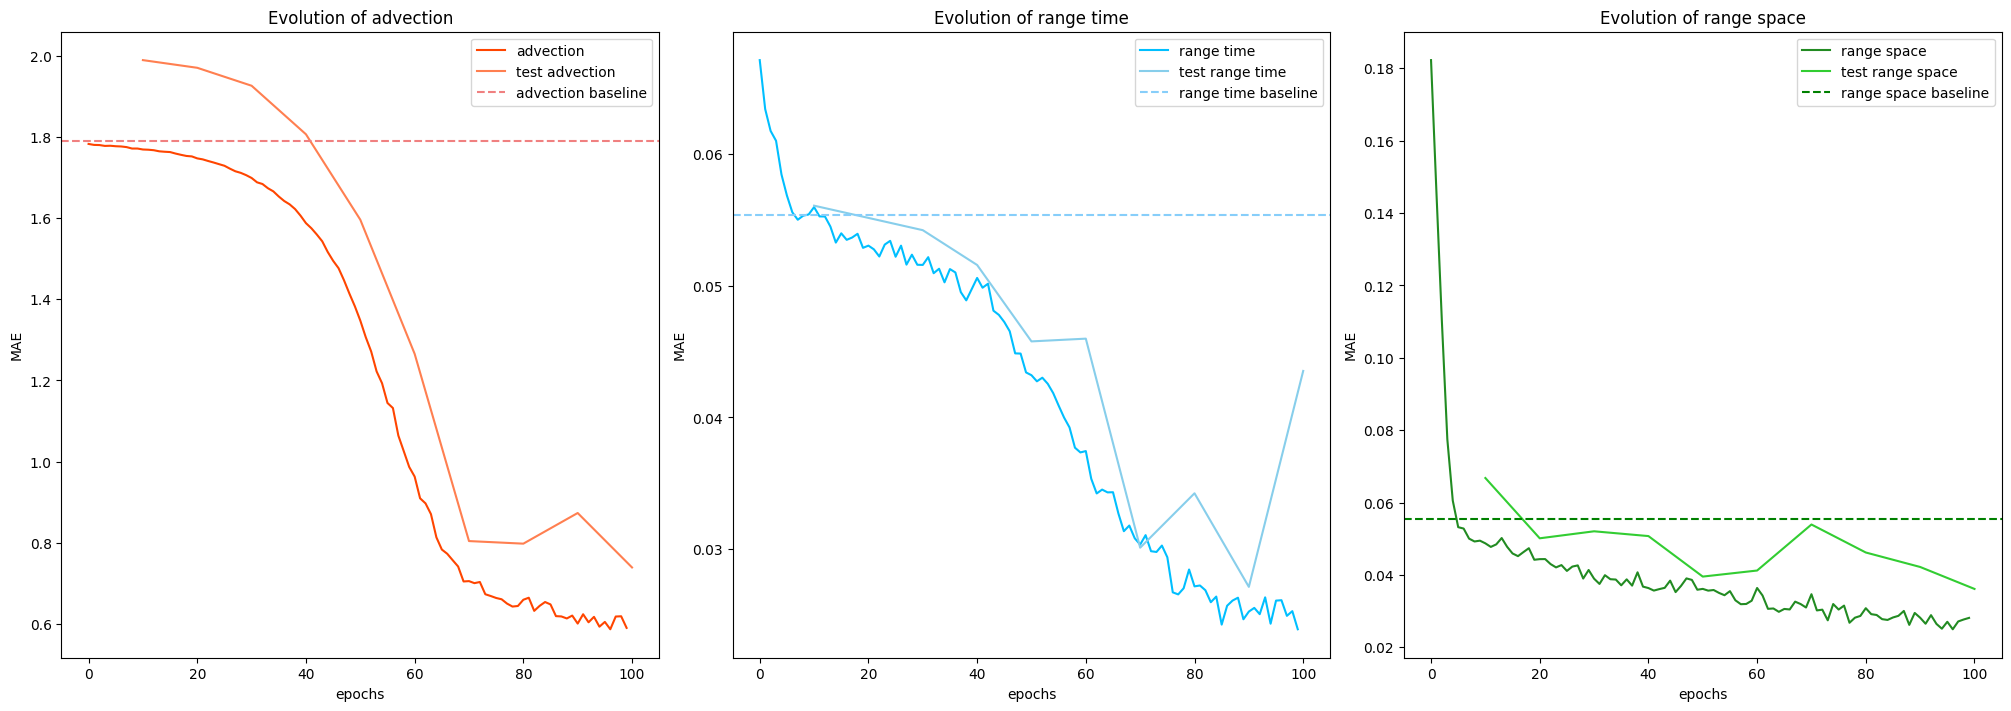

In [123]:
model_2D = CNN_network(in_channels=1, option="2D-CNN").to(device)

optimizer_2D = torch.optim.Adam(model_2D.parameters(), lr=5e-5)

all_loss_train_2D, time_train_2D, loss_final_train_2D, all_loss_test_2D, time_test_2D, theta_final_test_2D = train_test(model_2D, optimizer_2D, loader_grid, epoch_cnn)
fig_2D = plot_loss(all_loss_train_2D, all_loss_test_2D)

In [126]:
fig_2D.savefig(res_path+"/loss_evolution"+"/2D_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_2D.state_dict(), res_path+"/models"+"/2D_model.pth")

Epoch 150/150: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 150/150 [55:33<00:00, 22.22s/it, loss=1.6776, 0.0398 and 0.0260]


Time to train : 3362.23s
Train loss : range 1.6776187783926724 | std 0.03977107999803135
Test loss : range 1.6403897247463464 | std 0.046755433001785064


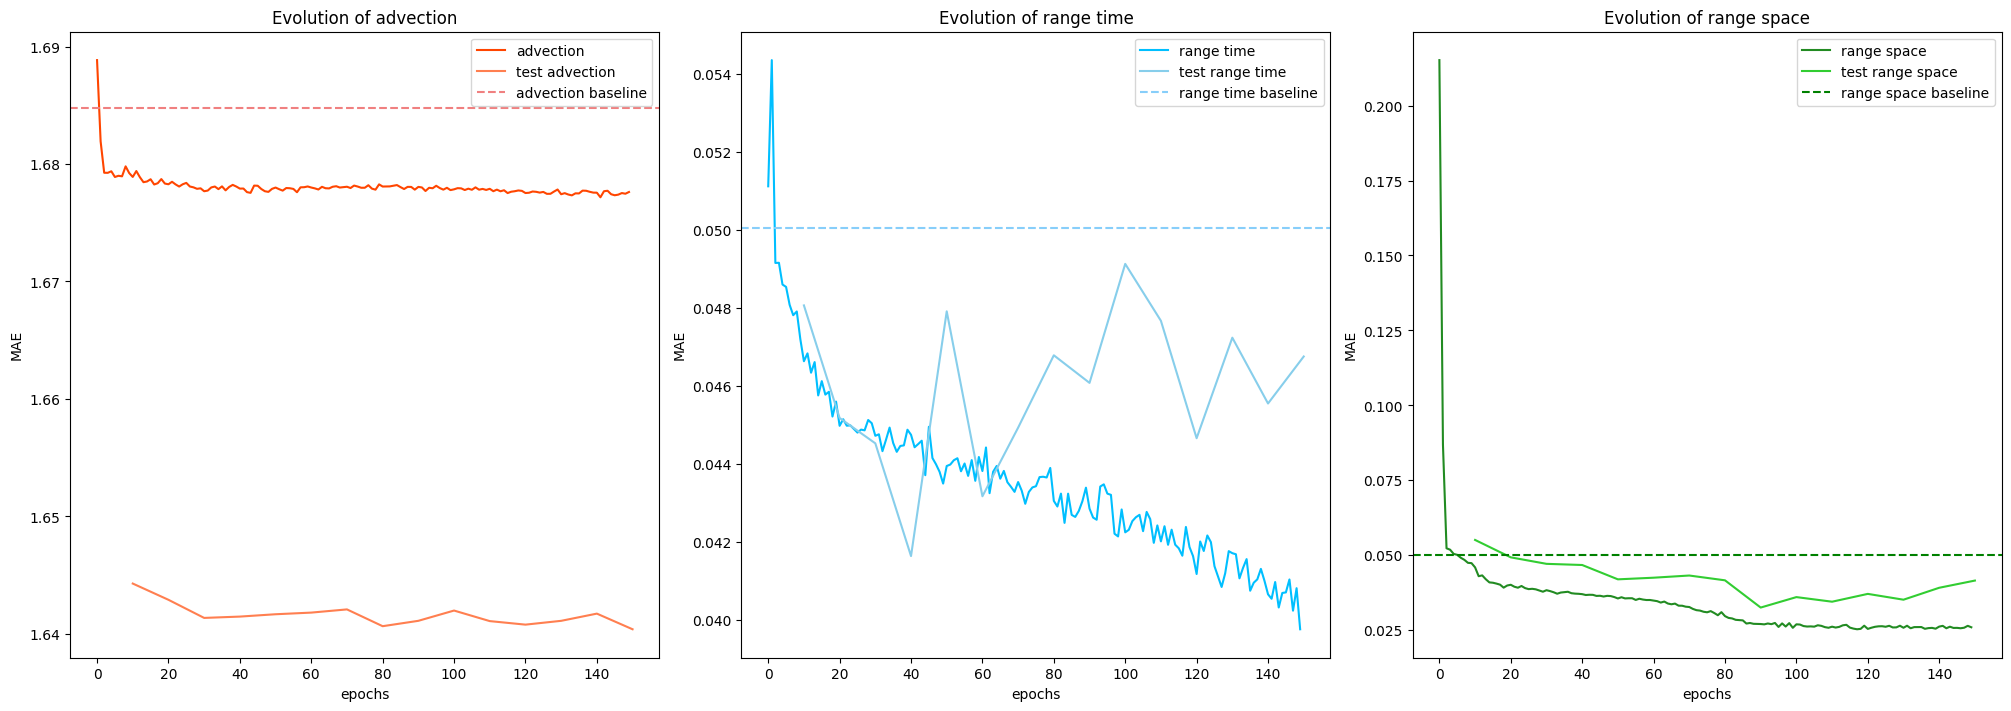

In [646]:
model_1D1D = CNN_network(in_channels=1, option="CNN").to(device)

optimizer_1D1D = torch.optim.Adam(model_1D1D.parameters(), lr=5e-5)

all_loss_train_1D1D, time_train_1D1D, loss_final_train_1D1D, all_loss_test_1D1D, time_test_1D1D, theta_final_test_1D1D = train_test(model_1D1D, optimizer_1D1D, loader_grid, epoch_cnn)
fig_1D1D = plot_loss(all_loss_train_1D1D, all_loss_test_1D1D)

In [647]:
fig_1D1D.savefig(res_path+"/loss_evolution"+"/1D1D_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_1D1D.state_dict(), res_path+"/models"+"/1D1D_model.pth")

Epoch 150/150: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 150/150 [55:44<00:00, 22.30s/it, loss=1.6728, 0.0421 and 0.0380]


Time to train : 3373.20s
Train loss : range 1.6727916415007786 | std 0.04207334325803377
Test loss : range 1.6432033819379286 | std 0.05335941602933342


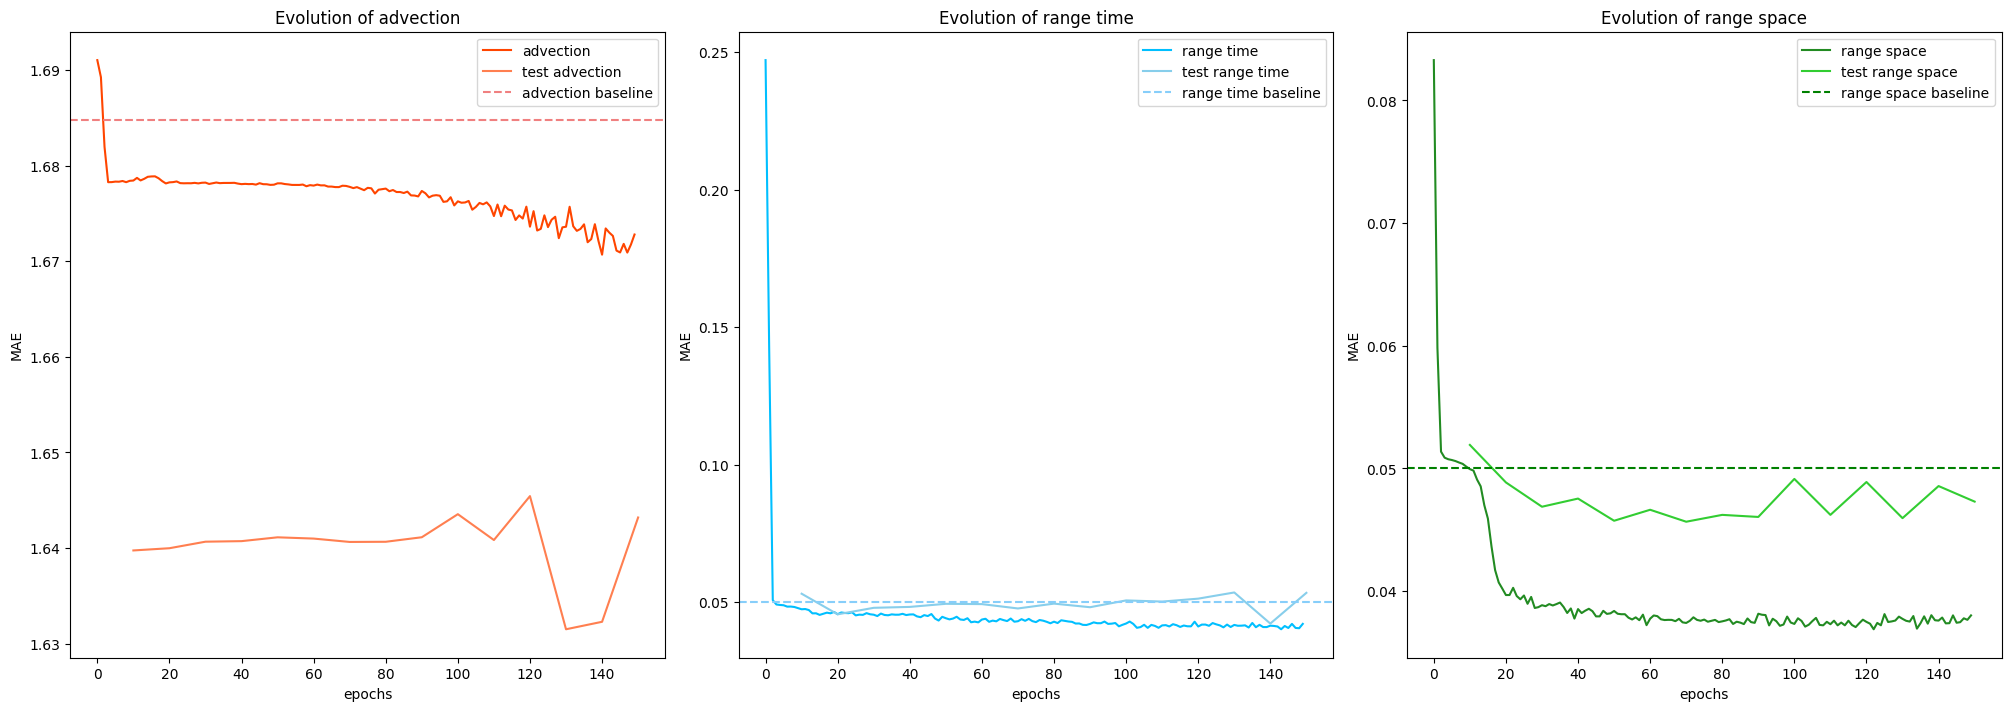

In [648]:
model_1DLSTM = CNN_network(in_channels=1, option="LSTM").to(device)

optimizer_1DLSTM = torch.optim.Adam(model_1DLSTM.parameters(), lr=5e-5)

all_loss_train_1DLSTM, time_train_1DLSTM, loss_final_train_1DLSTM, all_loss_test_1DLSTM, time_test_1DLSTM, theta_final_test_1DLSTM = train_test(model_1DLSTM, optimizer_1DLSTM, loader_grid, epoch_cnn)
fig_1DLSTM = plot_loss(all_loss_train_1DLSTM, all_loss_test_1DLSTM)

In [649]:
fig_1DLSTM.savefig(res_path+"/loss_evolution"+"/1DLSTM_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_1DLSTM.state_dict(), res_path+"/models"+"/1DLSTM_model.pth")

## NLS

### Functions

In [324]:
class GridNLSDataset(Dataset):
    def __init__(self, theta_size=200, time_size=40, space_size=40, deepset_size=5):

        self.time_size = time_size
        self.space_size = space_size
        
        self.theta_size = theta_size
        self.deepset_size = deepset_size

        self.adv = np.random.randint(-3,4,(theta_size,)) 
        self.range_time = np.random.uniform(0.05,0.25,(theta_size,))
        self.range_space = np.random.uniform(0.05,0.25,(theta_size,)) # torch.ones((batch_size,), dtype=int)*1
        
        self.pi = [torch.randperm(self.theta_size) for _ in range(self.deepset_size)]

    def __len__(self):
        return self.theta_size*2

    def get_theta(self):
        return torch.from_numpy(np.stack([self.adv,self.range_time, self.range_space]).T)

    def __getitem__(self, idx):

        is_perm = idx // self.theta_size
        idx = idx % self.theta_size

        model = gl.Model.createFromParam(gl.ECov.MATERN, ranges = [self.range_time[idx],self.range_space[idx]], param = 1, sill = 1**2, flagRange=False)

        shape_adv = abs(self.adv[idx])+1

        grid = gl.DbGrid.create(
            nx = [self.time_size,self.space_size * shape_adv],    
            dx = [1./self.time_size,1./self.space_size]
        )
        mesh = gl.MeshETurbo(grid)

        pop = gl.PrecisionOpMatrix(mesh, model.getCovAniso(0))

        batch = []
        theta = []
        
        for i in range(self.deepset_size):
            
            res = pop.simulateOne()
            res = res.reshape((self.time_size,self.space_size * shape_adv), order='F')

            s, t = np.meshgrid(np.arange(self.time_size), np.arange(self.space_size))
            offset = t.copy() * abs(self.adv[idx])
            s = s + offset

            if self.adv[idx] >= 0 :
                res = res[t,s]
            else :
                res = np.fliplr(res)
                res = res[t,s]
                res = np.fliplr(res)
            
            batch.append(res)

            if is_perm :
                theta.append(self.get_theta()[self.pi[i][idx]])
            else :
                theta.append(self.get_theta()[idx])

        batch = np.stack(batch)

        theta = torch.stack(theta)

        classi = torch.ones(self.deepset_size, dtype=int) * is_perm 

        
        return (torch.from_numpy(batch), theta, classi)           

In [377]:
dataset_grid_nls = GridNLSDataset(theta_size=train_size, time_size=time_size, space_size=space_size, deepset_size=deepset_size)
dataset_grid_nls_test = GridNLSDataset(theta_size=test_size, time_size=time_size, space_size=space_size, deepset_size=1)

loader_grid_nls = DataLoader(dataset_grid_nls, batch_size, shuffle=True)
loader_grid_nls_test = DataLoader(dataset_grid_nls_test, test_size*2, shuffle=False)

In [378]:
def epoch_nls(model, optimizer, loader):
    
    model.train()
    CE = nn.CrossEntropyLoss() # torch.nn.BCELoss(reduction="mean") 
    
    losses = []

    for i, (batched_data, theta, classi) in enumerate(loader):
        optimizer.zero_grad()

        batched_data, theta, classi = batched_data.to(device), theta.to(device), classi.to(device).flatten()

        batched_data = batched_data.reshape(-1, 1, batched_data.shape[2], batched_data.shape[3])   
        theta = theta.reshape(-1, theta.shape[2])   
        classi = classi.reshape(-1)   

        output = model(batched_data.float(), theta=theta)
        
        batch_loss = CE(output, classi)
        
        batch_loss.backward()
        optimizer.step()
        
        losses.append(batch_loss.mean().item())

    return {"mean":np.mean(losses)}

In [379]:
def estimate_likelihood_surface(model, simu, theta_grid):
    
    model.eval()
    
    L_values = []
    simu = simu.to(device)
    
    with torch.no_grad():
        t = tqdm(theta_grid)
        for theta in t:
            
            theta_t = theta.clone().unsqueeze(0).tile((len(simu), 1)).to(device)
            # print(simu.shape, theta_t.shape)
            h = model(simu.float(), theta=theta_t)
            
            # p = torch.softmax(h, dim=1)[:, 1]   # h[:,1]
            # L = p / (1 - p)
            # L_values.append(L)

            logL = h[:,1] - h[:,0]
            L_values.append(logL)

            # L = torch.log(L.unsqueeze(0)).detach().numpy()
            # L = torch.tensor(lg.predict_proba(L.T)[0, 1])     
            
    return torch.stack(L_values)

### Train

In [348]:
model_nls = CNN_network(in_channels=1, option="2D-CNN", nls=True).to(device)
# model_nls.load_state_dict(torch.load(f"results/global_smaller-{n_train}×{m_train}ntrain-{n_test}×{m_test}ntest"+"/models"+"/nls-classifier_model.pth", weights_only=True))

optimizer_nls = torch.optim.Adam(model_nls.parameters(), lr=1e-3)

In [303]:
all_loss_train_nls, time_train_nls = train_simple(model_nls, optimizer_nls, loader_grid_nls, epoch_nls)

Epoch 50/50: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 50/50 [11:25<00:00, 13.71s/it, loss={'mean': np.float64(0.3413187522441149)}]

Time to train : 685.70s
Train loss : 0.3413187522441149


Text(0, 0.5, 'Cross Entropy')

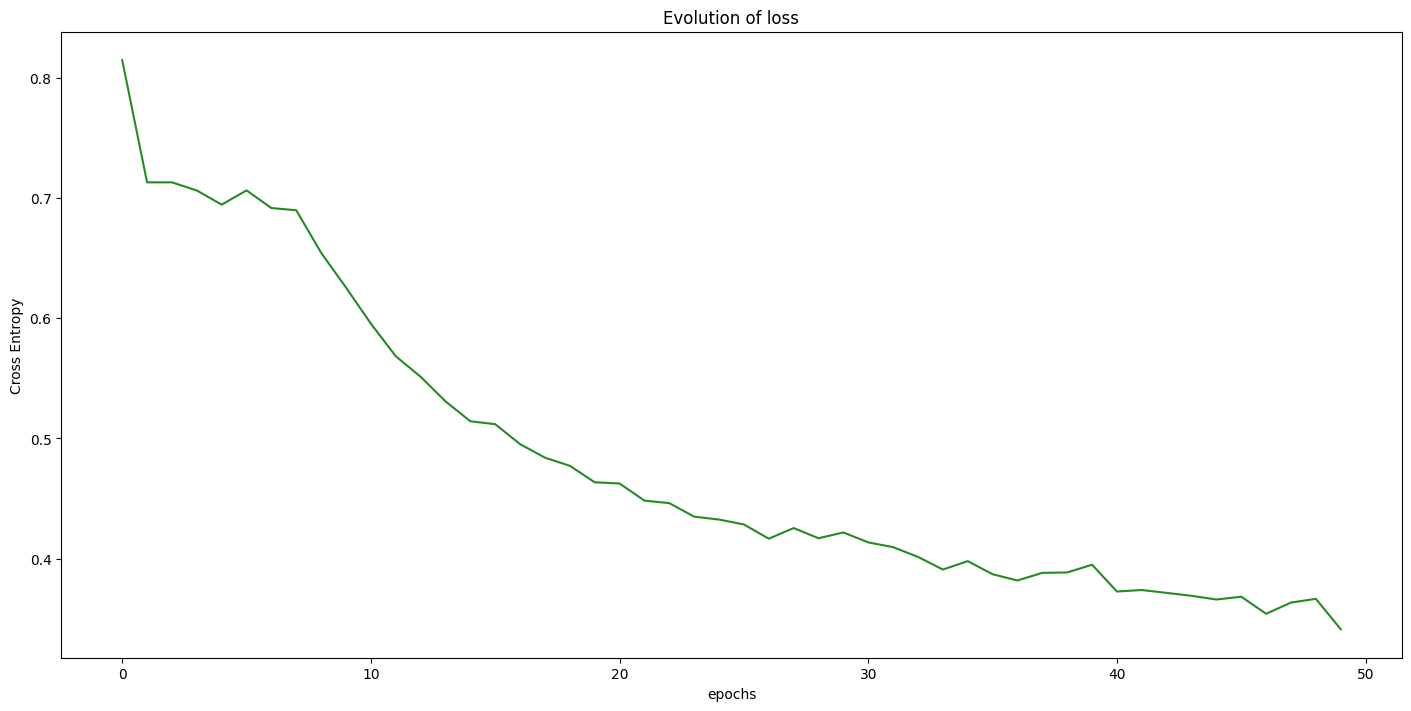

In [304]:
fig_nls, ax = plt.subplots(1, 1, figsize=(14, 7), constrained_layout=True)
ax.plot(all_loss_train_nls, 'forestgreen')

ax.set_title('Evolution of loss')
ax.set_xlabel('epochs')
ax.set_ylabel('Cross Entropy')

In [305]:
fig_nls.savefig(res_path+"/loss_evolution"+"/NLS-classifier_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_nls.state_dict(), res_path+"/models"+"/NLS-classifier_model.pth")

### Test

In [380]:
range_min, range_max = 0.05, 0.25
adv_min, adv_max = -3, 3

bounds = [(adv_min, adv_max), (range_min, range_max), (range_min, range_max)]

n_range = 8
n_adv = 8

range_vals = torch.linspace(range_min, range_max, n_range)
adv_vals = torch.linspace(adv_min, adv_max, n_adv)

R1, R2 = torch.meshgrid(range_vals, range_vals, indexing='ij')
R1, S = torch.meshgrid(R1.flatten(), adv_vals, indexing='ij')
R2, S = torch.meshgrid(R2.flatten(), adv_vals, indexing='ij')
theta_grid = torch.stack([S.flatten(), R1.flatten(), R2.flatten()], dim=1)

In [386]:
time_test_nls = time.time()

with torch.no_grad():
    for data_test, theta_test, _ in loader_grid_nls_test : 
        L_values = estimate_likelihood_surface(model_nls, data_test, theta_grid)
        output = theta_grid[torch.argmax(L_values,dim=0)]
        all_loss_test_nls = torch.abs(output - theta_test.squeeze(1)).detach().numpy()
        theta_final_nls = output.detach().numpy()
        
time_test_nls = time.time() - time_test_nls

print(f"\nTime to test : {time_test_nls:.2f}s")

print("Test loss :", np.mean(all_loss_test_nls,axis=0), "±", np.std(all_loss_test_nls,axis=0))

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 512/512 [00:09<00:00, 52.32it/s]

torch.Size([512, 60])
torch.Size([60])
torch.Size([60, 3])
torch.Size([60, 1, 3])

Time to test : 12.47s
(60, 3)
Test loss : [3.16666667 0.11084484 0.08942307] ± [2.20731108 0.06436333 0.05780276]


## Maximum likelihood

In [108]:
def matern_covariance_from_coords(coords, adv, range_time, range_space):

    t, s = grid

    s = s + t.copy() * adv

    sigma, nu = 1., 1.

    d2 = ((t - t.T)**2 / range_time**2) + ((s - s.T)**2 / range_space**2)
    d = np.sqrt(d2 + 1e-12) 

    res = (sigma**2 * (2**(1-nu) / gamma(nu)) * (np.sqrt(2*nu) * d)**nu * kv(nu, np.sqrt(2*nu) * d))
    
    np.fill_diagonal(res, sigma**2)

    return res

In [109]:
def nll(theta, coords, values, eps=1e-6): 
    # https://soft.mines-paristech.fr/gstlearn/demos-latest/python/Tuto_LogLikelihood.html

    adv, range_time, range_space = theta
    cov = matern_covariance_from_coords(coords, adv, range_time, range_space)
    cov += eps * np.eye(cov.shape[0])

    L = linalg.cholesky(cov) 

    # solve Σ^{-1} @ values 
    alpha = linalg.cho_solve((L, False), values) 

    # Compute values.T @ Σ^{-1} @ values 
    quad = float(np.dot(values,alpha))

    # det term, https://math.stackexchange.com/questions/3158303/using-cholesky-decomposition-to-compute-covariance-matrix-determinant
    logdet = 2.0 * np.sum(np.log(np.diag(L)))

    return 0.5 * (logdet + quad + values.size * np.log(2.0 * np.pi))

In [110]:
range_min, range_max = 0.05, 0.5
adv_min, adv_max = -3, 3

bounds = [(adv_min, adv_max), (range_min, range_max), (range_min, range_max)]

In [111]:
def mle_matern(coords, values, theta0=(0,.2, .2)):

    def obj(theta):
        return nll(theta, coords, values)

    res = minimize(obj, theta0, method="Nelder-Mead", bounds=bounds, options={"maxiter":2000})
    return res.x, res

In [112]:
all_loss_test_ML = np.zeros((len(dataset_grid_test),3))
theta_final_ML = np.zeros((len(dataset_grid_test),3))

dataset_mle = GridDataset(theta_size=test_size, time_size=time_size, space_size=space_size, deepset_size=1)

grid = np.meshgrid(np.linspace(0,1,time_size), np.linspace(0,1,time_size), indexing='ij')
grid = ([grid[0].reshape(-1, 1), grid[1].reshape(-1, 1)])

time_test_ML = time.time()

for i, (data_test, theta_test, _) in enumerate(dataset_mle) : 
    
    output, _ = mle_matern(grid, data_test.flatten().detach().numpy())

    all_loss_test_ML[i] = np.abs(output - theta_test.flatten().detach().numpy())
    theta_final_ML[i] = output

    print(i, end='|')

    # print(f"| RANGE {output[0]:.4f} - {theta_test[0]:.4f} = {abs(output[0]-theta_test[0]):.4f} | STD {output[1]:.4f} - {theta_test[1]:.4f} = {abs(output[1]-theta_test[1]):.4f} |")

time_test_ML = time.time() - time_test_ML

print(f"\n\nTime to test : {time_test_ML:.2f}s")

print("Test loss :", np.mean(all_loss_test_ML,axis=0), "±", np.std(all_loss_test_ML,axis=0))

0|1|2|3|4|5|6|7|8|9|10|11|12|13|14|15|16|17|18|19|

Time to test : 1400.25s
Test loss : [0.38284003 0.07327259 0.02481868] ± [0.89858435 0.06108345 0.0316696 ]


## Conclusion

In [113]:
methods = ['2D-CNN', '1D1D-CNN','1DLSTM']

loss_adv = [
    loss_final_train_2D[:, 0],
    loss_final_train_1D1D[:, 0],
    loss_final_train_1DLSTM[:, 0],
]

loss_range_time = [
    loss_final_train_2D[:, 1],
    loss_final_train_1D1D[:, 1],
    loss_final_train_1DLSTM[:, 1],
]

loss_range_space = [
    loss_final_train_2D[:, 2],
    loss_final_train_1D1D[:, 2],
    loss_final_train_1DLSTM[:, 2],
]

### Boxplot
fig_box_train, axs = plt.subplots(1, 3, figsize=(18, 6))

axs[0].boxplot(loss_adv, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='orangered', alpha=0.6), 
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[0].set_title("MAE – advection")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_range_time, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='deepskyblue', alpha=0.6),
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[1].set_title("MAE – range time")

axs[2].boxplot(loss_range_space, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='forestgreen', alpha=0.6),
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[2].set_title("MAE – range space")

based, _ = baseline_mae(dataset_grid)

axs[0].axhline(based[0],color='coral', ls='--', label='avection baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='range time baseline')
axs[2].axhline(based[2],color='green', ls='--', label='range space baseline')

axs[0].legend()
axs[1].legend()
axs[2].legend()

plt.suptitle("Train error comparaison")
plt.tight_layout()
plt.show()

# fig_box_train.savefig(res_path+"/conclusion_graphs"+"/score_train.pdf", format="pdf", bbox_inches="tight")
fig_box_train.savefig(res_path+"/conclusion_graphs"+"/score_train.png", format="png", bbox_inches="tight")

NameError: name 'loss_final_train_2D' is not defined

/tmp/ipykernel_1075352/2297823332.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(loss_adv, labels=methods, patch_artist=True,
/tmp/ipykernel_1075352/2297823332.py:33: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(loss_range_time, labels=methods, patch_artist=True,
/tmp/ipykernel_1075352/2297823332.py:38: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[2].boxplot(loss_range_space, labels=methods, patch_artist=True,


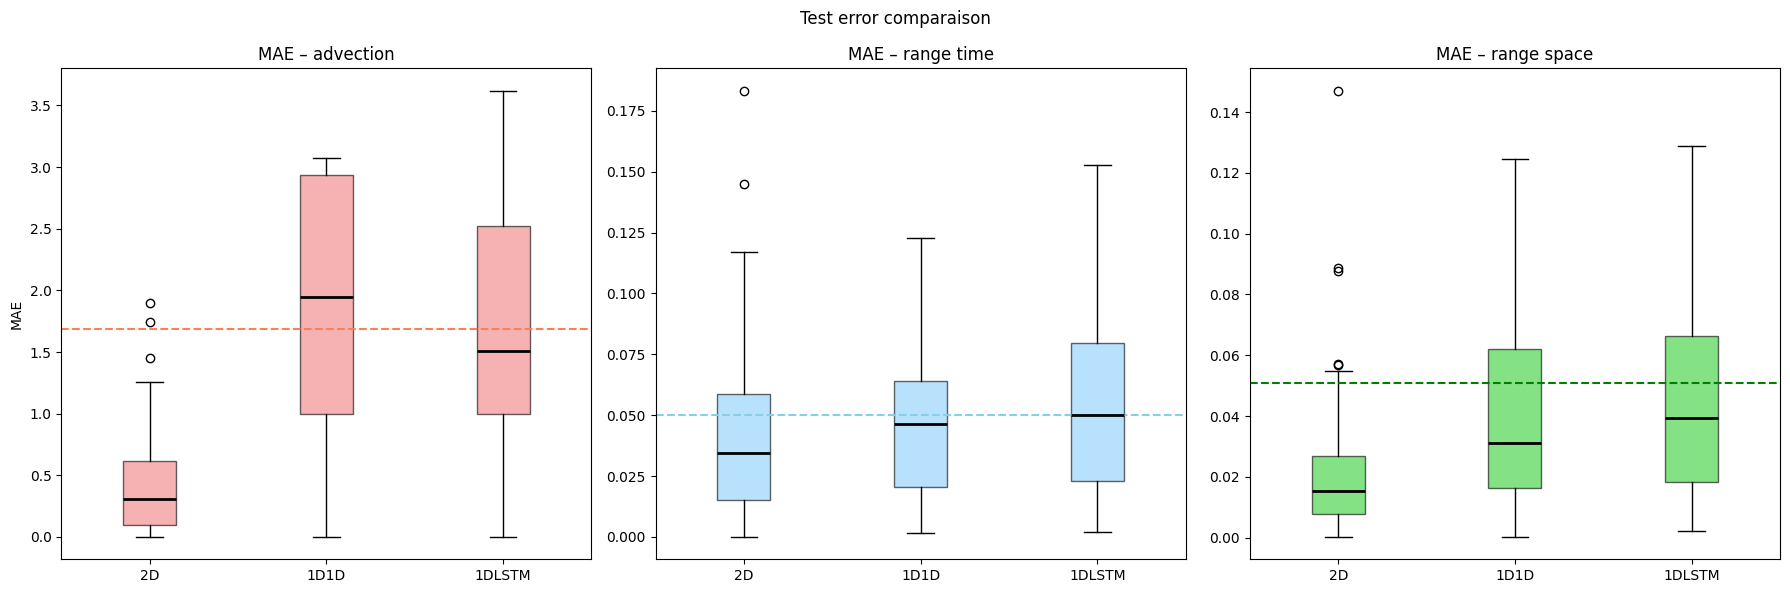

In [672]:
methods = ['2D', '1D1D','1DLSTM'] # 'CNN-NLS'

loss_adv = [
    abs(theta_final_test_2D[:, 0] - dataset_grid_test.get_theta()[:, 0]),
    abs(theta_final_test_1D1D[:, 0] - dataset_grid_test.get_theta()[:, 0]),
    abs(theta_final_test_1DLSTM[:, 0] - dataset_grid_test.get_theta()[:, 0]),
    # all_loss_test_nls[:,0]
]

loss_range_time = [
    abs(theta_final_test_2D[:, 1] - dataset_grid_test.get_theta()[:, 1]),
    abs(theta_final_test_1D1D[:, 1] - dataset_grid_test.get_theta()[:, 1]),
    abs(theta_final_test_1DLSTM[:, 1] - dataset_grid_test.get_theta()[:, 1]),
    # all_loss_test_nls[:,1]
]

loss_range_space = [
    abs(theta_final_test_2D[:, 2] - dataset_grid_test.get_theta()[:, 2]),
    abs(theta_final_test_1D1D[:, 2] - dataset_grid_test.get_theta()[:, 2]),
    abs(theta_final_test_1DLSTM[:, 2] - dataset_grid_test.get_theta()[:, 2]),
    # all_loss_test_nls[:,1]
]

### Boxplot
fig_box_test, axs = plt.subplots(1, 3, figsize=(18, 6))

axs[0].boxplot(loss_adv, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightcoral', alpha=0.6), 
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[0].set_title("MAE – advection")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_range_time, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightskyblue', alpha=0.6),
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[1].set_title("MAE – range time")

axs[2].boxplot(loss_range_space, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='limegreen', alpha=0.6),
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[2].set_title("MAE – range space")

based, _ = baseline_mae(dataset_grid)

axs[0].axhline(based[0],color='coral', ls='--', label='avection baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='range time baseline')
axs[2].axhline(based[2],color='green', ls='--', label='range space baseline')

fig_box_test.suptitle("Test error comparaison")
plt.tight_layout()
plt.show()

# fig_box_test.savefig(res_path+"/conclusion_graphs"+"/score_test.pdf", format="pdf", bbox_inches="tight")
fig_box_test.savefig(res_path+"/conclusion_graphs"+"/score_test.png", format="png", bbox_inches="tight")

axs[0].set_ylim(top=based[0]+.05)
axs[1].set_ylim(top=based[1]+.05)
axs[2].set_ylim(top=based[2]+.05)

fig_box_test.suptitle("Test error comparaison cropped")

fig_box_test.savefig(res_path+"/conclusion_graphs"+"/score_test_cropped.png", format="png", bbox_inches="tight")

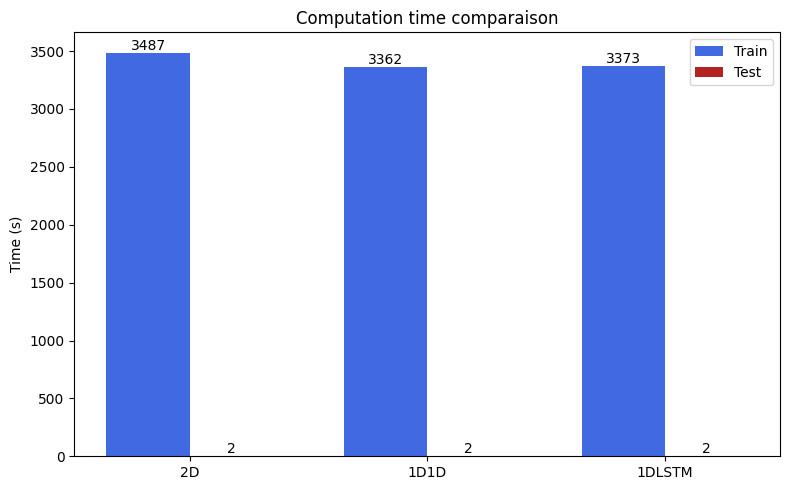

In [669]:
### Time
train_times = [time_train_2D, time_train_1D1D, time_train_1DLSTM]  
test_times = [time_test_2D, time_test_1D1D, time_test_1DLSTM]

x = np.arange(len(methods))
width = 0.35

fig_time, ax = plt.subplots(figsize=(8, 5))
bar1 = ax.bar(x - width/2, train_times, width, label='Train', color='royalblue')
bar2 = ax.bar(x + width/2, test_times, width, label='Test', color='firebrick')

for rect in bar1 + bar2:
    height = rect.get_height()
    plt.text(rect.get_x() + rect.get_width() / 2.0, height, f'{height:.0f}', ha='center', va='bottom')

ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel("Time (s)")
ax.set_title("Computation time comparaison")
ax.legend()

plt.tight_layout()
plt.show()

# fig_time.savefig(res_path+"/conclusion_graphs"+"/time.pdf", format="pdf", bbox_inches="tight")
fig_time.savefig(res_path+"/conclusion_graphs"+"/time.png", format="png", bbox_inches="tight")

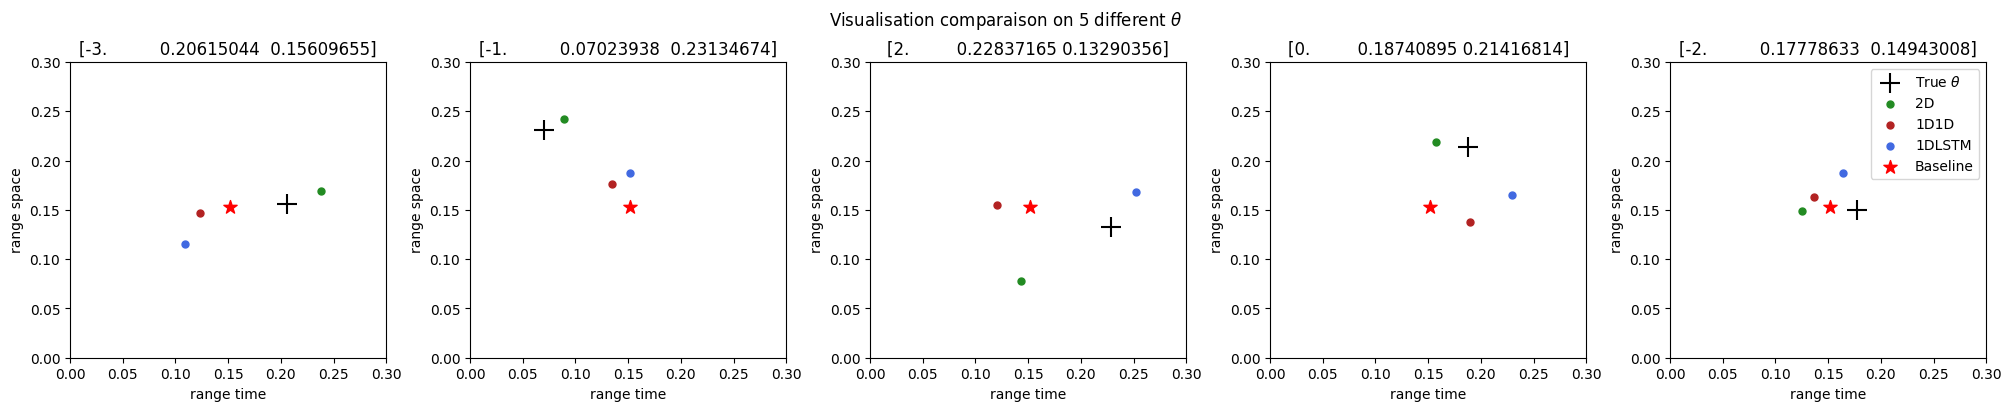

In [686]:
range_min, range_max = 0.05, 0.25
adv_min, adv_max = -3, 3

methods = ['2D', '1D1D','1DLSTM'] #,'CNN-NLS']
colors = ["forestgreen", "firebrick", "royalblue"] #, "orchid"]
thetas_final = [theta_final_test_2D, theta_final_test_1D1D, theta_final_test_1DLSTM]

fig_target, axs = plt.subplots(1, 5, figsize=(20,4), constrained_layout=True)

_, based_theta = baseline_mae(dataset_grid)

for j in range(min(deepset_size,5)):
    
    true_theta = dataset_grid_test.get_theta()[j].detach().numpy()

    axs[j].scatter(true_theta[1], true_theta[2], s=200, color='black', marker="+", label=r"True $\theta$") 
        
    axs[j].set_xlabel('range time')
    axs[j].set_ylabel('range space')
    axs[j].set_title(str(true_theta))

    axs[j].set_xlim([range_min-.05, range_max+.05])
    axs[j].set_ylim([range_min-.05, range_max+.05])

    for method, color, thetas in zip(methods, colors, thetas_final) :

        axs[j].scatter(thetas[np.arange(1)+j,1],
                       thetas[np.arange(1)+j,2],
                       s=100, color=color, marker=".", label=method) 

    axs[j].scatter(based_theta[1],based_theta[2], s=100, color='red', marker="*",label='Baseline')

plt.suptitle(r"Visualisation comparaison on 5 different $\theta$")
plt.legend()

# fig_target.savefig(res_path+"/conclusion_graphs"+"/target.pdf", format="pdf", bbox_inches="tight")
fig_target.savefig(res_path+"/conclusion_graphs"+"/target.png", format="png", bbox_inches="tight")

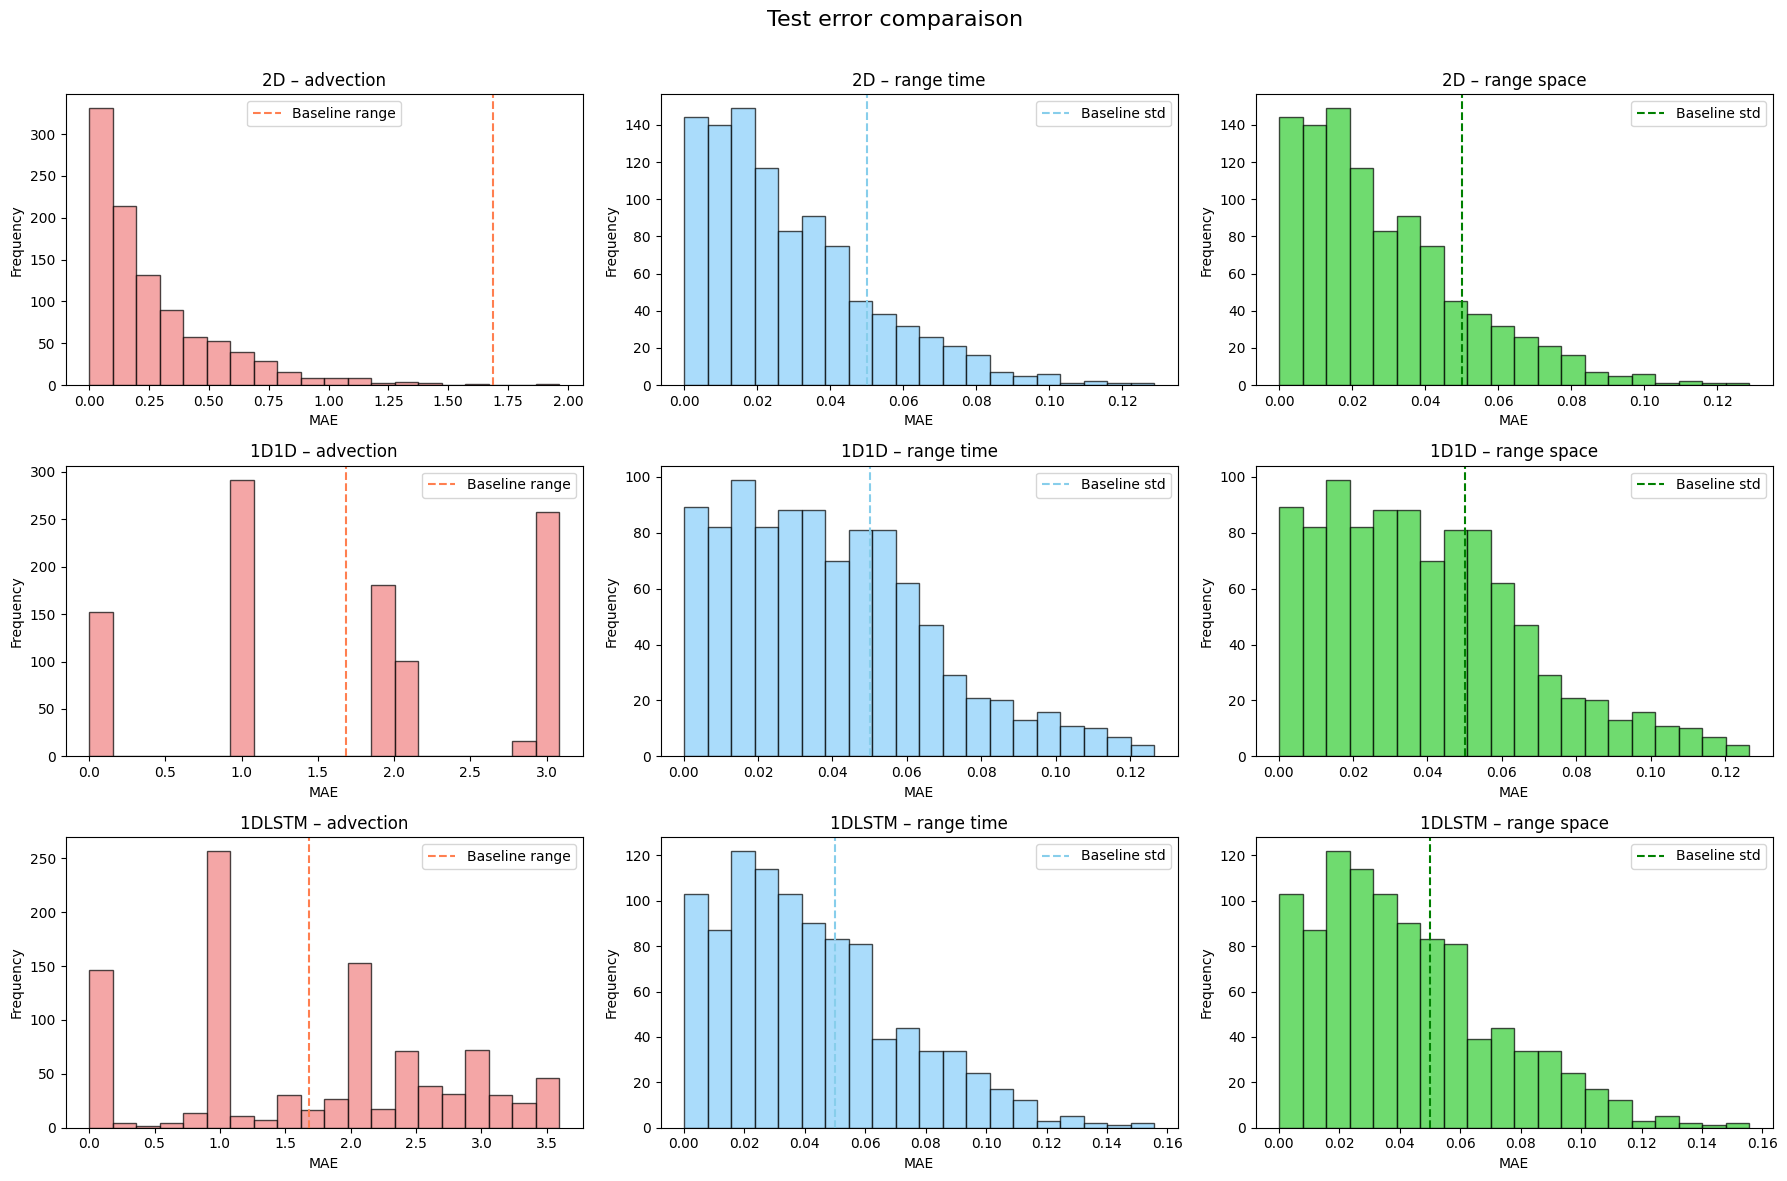

In [690]:
methods = ['2D', '1D1D','1DLSTM']

loss_adv = [
    abs(theta_final_test_2D[:, 0] - dataset_grid_test.get_theta()[:, 0]),
    abs(theta_final_test_1D1D[:, 0] - dataset_grid_test.get_theta()[:, 0]),
    abs(theta_final_test_1DLSTM[:, 0] - dataset_grid_test.get_theta()[:, 0]),
    # all_loss_test_nls[:,0]
]

loss_range_time = [
    abs(theta_final_test_2D[:, 1] - dataset_grid_test.get_theta()[:, 1]),
    abs(theta_final_test_1D1D[:, 1] - dataset_grid_test.get_theta()[:, 1]),
    abs(theta_final_test_1DLSTM[:, 1] - dataset_grid_test.get_theta()[:, 1]),
    # all_loss_test_nls[:,1]
]

loss_range_space = [
    abs(theta_final_test_2D[:, 2] - dataset_grid_test.get_theta()[:, 2]),
    abs(theta_final_test_1D1D[:, 2] - dataset_grid_test.get_theta()[:, 2]),
    abs(theta_final_test_1DLSTM[:, 2] - dataset_grid_test.get_theta()[:, 2]),
    # all_loss_test_nls[:,1]
]

fig_hist, axs = plt.subplots(len(loss_adv), 3, figsize=(18, 4*len(loss_adv)))
fig_hist.suptitle("Test error comparaison", fontsize=16)

for i, method in enumerate(methods):

    axs[i, 0].hist(loss_range[i], bins=20, color='lightcoral', alpha=0.7, edgecolor='black')
    axs[i, 0].axvline(based[0], color='coral', linestyle='--', label='Baseline range')
    axs[i, 0].set_title(f"{method} – advection")
    axs[i, 0].set_xlabel("MAE")
    axs[i, 0].set_ylabel("Frequency")
    axs[i, 0].legend()

    axs[i, 1].hist(loss_std[i], bins=20, color='lightskyblue', alpha=0.7, edgecolor='black')
    axs[i, 1].axvline(based[1], color='skyblue', linestyle='--', label='Baseline std')
    axs[i, 1].set_title(f"{method} – range time")
    axs[i, 1].set_xlabel("MAE")
    axs[i, 1].set_ylabel("Frequency")
    axs[i, 1].legend()

    axs[i, 2].hist(loss_std[i], bins=20, color='limegreen', alpha=0.7, edgecolor='black')
    axs[i, 2].axvline(based[1], color='green', linestyle='--', label='Baseline std')
    axs[i, 2].set_title(f"{method} – range space")
    axs[i, 2].set_xlabel("MAE")
    axs[i, 2].set_ylabel("Frequency")
    axs[i, 2].legend()

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

fig_hist.savefig(res_path+"/conclusion_graphs"+"/score_test_hist.png", format="png", bbox_inches="tight")

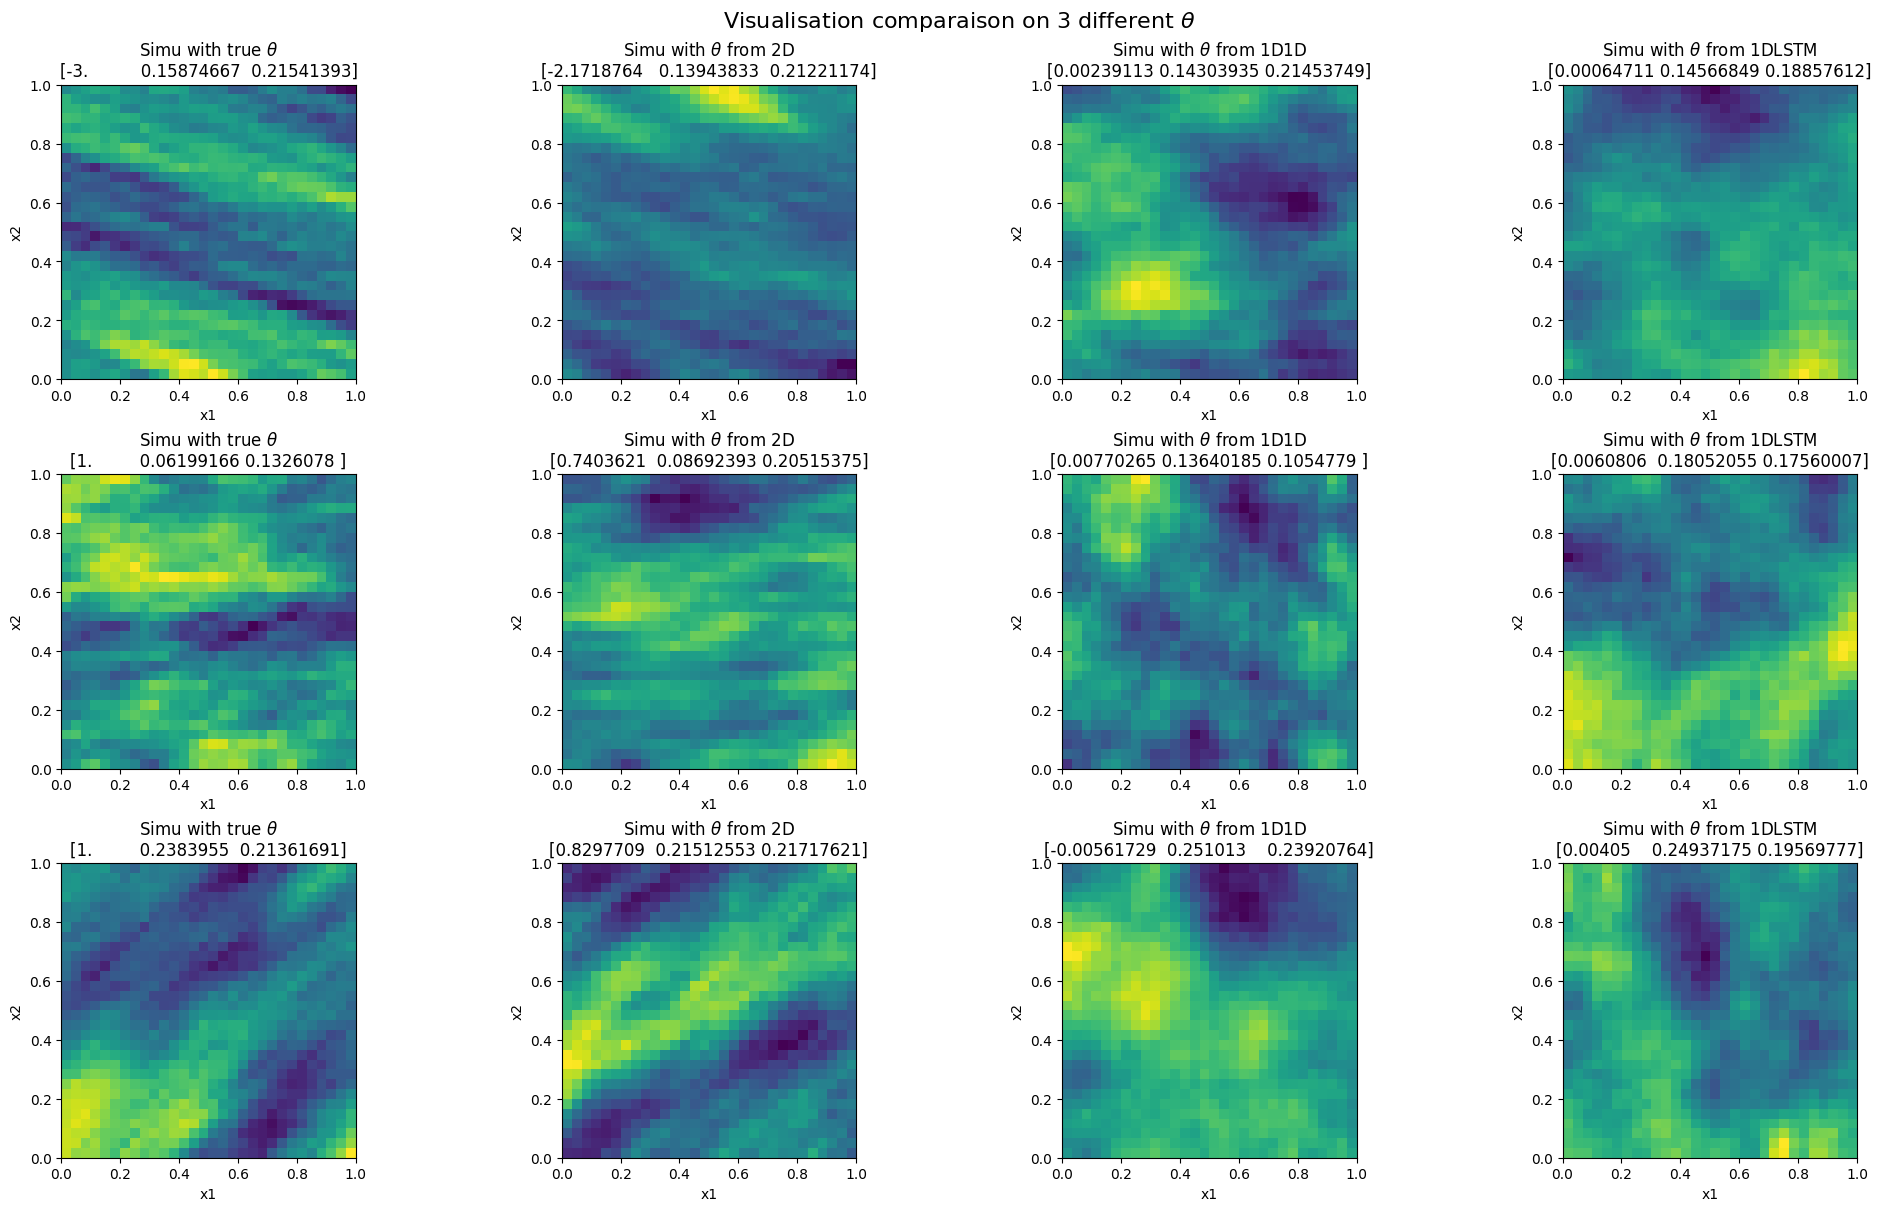

In [68]:
n = 3
fig_map, axs = plt.subplots(n, 4, figsize=(20,n*4), constrained_layout=True)

methods = ['2D', '1D1D','1DLSTM']
models = [model_2D, model_1D1D, model_1DLSTM]
# thetas_final = [theta_final_test_2D, theta_final_test_1D1D, theta_final_test_1DLSTM]
# losses = [all_loss_test_2D[-1], all_loss_test_1D1D[-1], all_loss_test_1DLSTM[-1]]

for i in range(n):
    sample, true_theta, _ = dataset_grid_test[i]
    true_theta = true_theta[0].detach().numpy()
    
    axs[i,0].imshow(sample[0], cmap='viridis', extent=[0,1,0,1])
        
    axs[i,0].set_xlabel('x1')
    axs[i,0].set_ylabel('x2')
    axs[i,0].set_title(r'Simu with true $\theta$'+'\n'+str(true_theta))
    
    for j, (method, model) in enumerate(zip(methods, models)) :

        theta_pred = model(sample.unsqueeze(0).float(), deepset=torch.tensor([0]))[0]
        sample_pred = simulate_matern_grid(time_size, space_size, torch.round(theta_pred[0]).to(int).detach().numpy(), torch.max(theta_pred[1],torch.tensor(0.05)), torch.max(theta_pred[2],torch.tensor(0.05)), deepset_size=1)[0]
            
        # sample = sample['Simu'].reshape(100, 100)
        axs[i,j+1].imshow(sample_pred, cmap='viridis', extent=[0,1,0,1]) #, origin='lower', extent=[0,1,0,1], cmap='viridis')
            
        axs[i,j+1].set_xlabel('x1')
        axs[i,j+1].set_ylabel('x2')
        axs[i,j+1].set_title(r'Simu with $\theta$ from '+method+'\n'+str(theta_pred.detach().numpy()))
        

fig_map.suptitle(r"Visualisation comparaison on "+str(n)+r" different $\theta$", fontsize=16)

# fig_map.savefig(res_path+"/conclusion_graphs"+"/visualisation.pdf", format="pdf", bbox_inches="tight")
fig_map.savefig(res_path+"/conclusion_graphs"+"/visualisation.png", format="png", bbox_inches="tight")

plt.show()

In [69]:
results = {
    "all_loss_train": {
        "2D": all_loss_train_2D,
        "1D1D": all_loss_train_1D1D,
        "1DLSTM": all_loss_train_1DLSTM,
    },
    "all_loss_test": {
        "2D": all_loss_test_2D,
        "1D1D": all_loss_test_1D1D,
        "1DLSTM": all_loss_test_1DLSTM,
        # "NLS": all_loss_test_nls,
    },
    "loss_final": {
        "2D": loss_final_train_2D,
        "1D1D": loss_final_train_1D1D,
        "1DLSTM": loss_final_train_1DLSTM,
    },
    "theta_final": {
        "2D": theta_final_test_2D,
        "1D1D": theta_final_test_1D1D,
        "1DLSTM": theta_final_test_1DLSTM,
        # "NLS": theta_final_nls,
    },
    "times": {
        "time_train_2D": time_train_2D,
        "time_test_2D": time_test_2D,
        "time_train_1D1D": time_train_1D1D,
        "time_test_1D1D": time_test_1D1D,
        "time_train_1DLSTM": time_train_1DLSTM,
        "time_test_1DLSTM": time_test_1DLSTM,
        # "time_train_nls": time_train_nls,
        # "time_test_nls": time_test_nls,
    },
}

torch.save(results, res_path + "/results.pt")

NameError: name 'all_loss_train_2D' is not defined